import required libraries and Load the dataset

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# Set random seed for reproducibility
np.random.seed(42)

# Load the real dataset
# Note: Ensure 'bestsellers_with_categories_2022_03_27[1].csv' is in your working directory
df = pd.read_csv(r"C:\Users\RUDZANI   NETHENGWE\Downloads\archive (7)\bestsellers_with_categories_2022_03_27.csv")


display(df.head())

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,"Act Like a Lady, Think Like a Man: What Men Re...",Steve Harvey,4.6,5013,17,2009,Non Fiction
1,Arguing with Idiots: How to Stop Small Minds a...,Glenn Beck,4.6,798,5,2009,Non Fiction
2,"Breaking Dawn (The Twilight Saga, Book 4)",Stephenie Meyer,4.6,9769,13,2009,Fiction
3,Crazy Love: Overwhelmed by a Relentless God,Francis Chan,4.7,1542,14,2009,Non Fiction
4,Dead And Gone: A Sookie Stackhouse Novel (Sook...,Charlaine Harris,4.6,1541,4,2009,Fiction


a. Exploratory data analysis 

Inspect dataset

In [2]:
# inspect the dataset

print("="*60)
print("1. DATASET BASIC INFO & SHAPE")
print("="*60)
print(f"Total Rows (Records): {df.shape[0]}")
print(f"Total Columns (Features): {df.shape[1]}")
print("\nData Types & Non-Null Counts:")
print(df.info())

print("\n" + "="*60)
print("2. FIRST 5 ROWS OF THE DATASET")
print("="*60)
display(df.head())

print("\n" + "="*60)
print("3. DESCRIPTIVE STATISTICS (Numerical Features)")
print("="*60)
print(df.describe().T)

print("\n" + "="*60)
print("4. DESCRIPTIVE STATISTICS (Categorical Features)")
print("="*60)
print(df.describe(include=['O']).T)

print("\n" + "="*60)
print("5. UNIQUE VALUES CHECK")
print("="*60)
for col in df.columns:
    print(f"Unique values in '{col}': {df[col].nunique()}")

# Check for missing values and duplicates
print("Missing Values per Column:\n", df.isnull().sum())
print(f"Duplicate rows count: {df.duplicated().sum()}")

# Drop duplicates if any
df = df.drop_duplicates().reset_index(drop=True)

# Engineering a Binary Target:
# Since all books in this dataset are bestsellers, we define a high-performance 
# target: 1 if User Rating >= 4.8 AND Reviews are greater than the median, else 0.
review_median = df['Reviews'].median()
df['is_top_tier'] = ((df['User Rating'] >= 4.8) & (df['Reviews'] > review_median)).astype(int)

print("\n--- Target Class Distribution ---")
print(df['is_top_tier'].value_counts(normalize=True) * 100)
print(df['is_top_tier'].value_counts())

1. DATASET BASIC INFO & SHAPE
Total Rows (Records): 700
Total Columns (Features): 7

Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         700 non-null    object 
 1   Author       700 non-null    object 
 2   User Rating  700 non-null    float64
 3   Reviews      700 non-null    int64  
 4   Price        700 non-null    int64  
 5   Year         700 non-null    int64  
 6   Genre        700 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 38.4+ KB
None

2. FIRST 5 ROWS OF THE DATASET


,Name,Author,User Rating,Reviews,Price,Year,Genre
0,"Act Like a Lady, Think Like a Man: What Men Re...",Steve Harvey,4.6,5013,17,2009,Non Fiction
1,Arguing with Idiots: How to Stop Small Minds a...,Glenn Beck,4.6,798,5,2009,Non Fiction
2,"Breaking Dawn (The Twilight Saga, Book 4)",Stephenie Meyer,4.6,9769,13,2009,Fiction
3,Crazy Love: Overwhelmed by a Relentless God,Francis Chan,4.7,1542,14,2009,Non Fiction
4,Dead And Gone: A Sookie Stackhouse Novel (Sook...,Charlaine Harris,4.6,1541,4,2009,Fiction



3. DESCRIPTIVE STATISTICS (Numerical Features)
             count          mean           std     min      25%      50%  \
User Rating  700.0      4.639857      0.218586     3.3     4.50      4.7   
Reviews      700.0  19255.195714  23613.443875    37.0  4987.25  10284.0   
Price        700.0     12.700000      9.915162     0.0     7.00     11.0   
Year         700.0   2015.500000      4.034011  2009.0  2012.00   2015.5   

                 75%       max  
User Rating      4.8       4.9  
Reviews      23358.0  208917.0  
Price           15.0     105.0  
Year          2019.0    2022.0  

4. DESCRIPTIVE STATISTICS (Categorical Features)
       count unique                                                top freq
Name     700    441  Publication Manual of the American Psychologic...   10
Author   700    305                                        Jeff Kinney   14
Genre    700      2                                        Non Fiction  388

5. UNIQUE VALUES CHECK
Unique values in 'Name': 441

Exploratory Data Analysis
(Data Cleaning & Target Engineering)

In [3]:
# Check for missing values and duplicates
print("Missing Values per Column:\\n", df.isnull().sum())
print(f"Duplicate rows count: {df.duplicated().sum()}")

# Drop exact duplicate rows if any; original source file is not modified.
df = df.drop_duplicates().reset_index(drop=True)

# Feature Engineering from text and categorical attributes
df['Title_Length'] = df['Name'].astype(str).apply(len)
df['Author_Frequency'] = df['Author'].map(df['Author'].value_counts())
df['Genre_Encoded'] = df['Genre'].astype('category').cat.codes

# Define target.
# Important limitation: User Rating and Reviews define this label, so they are
# excluded from model predictors later to avoid target leakage.
review_median = df['Reviews'].median()
df['is_top_tier'] = ((df['User Rating'] >= 4.8) & (df['Reviews'] > review_median)).astype(int)

print("\\nTarget Class Distribution:")
print(df['is_top_tier'].value_counts())


Missing Values per Column:\n Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
is_top_tier    0
dtype: int64
Duplicate rows count: 0
\nTarget Class Distribution:
is_top_tier
0    545
1    155
Name: count, dtype: int64


Exploratory Data Analysis - EDA

Exploratory Data Analysis (Visualizations)
We examine feature distributions, correlations, and relationships to understand patterns in book ratings, pricing, and review volumes.

C:\Users\RUDZANI   NETHENGWE\AppData\Local\Temp\ipykernel_16824\1025977050.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Genre', y='Price', data=df, palette='Set2')


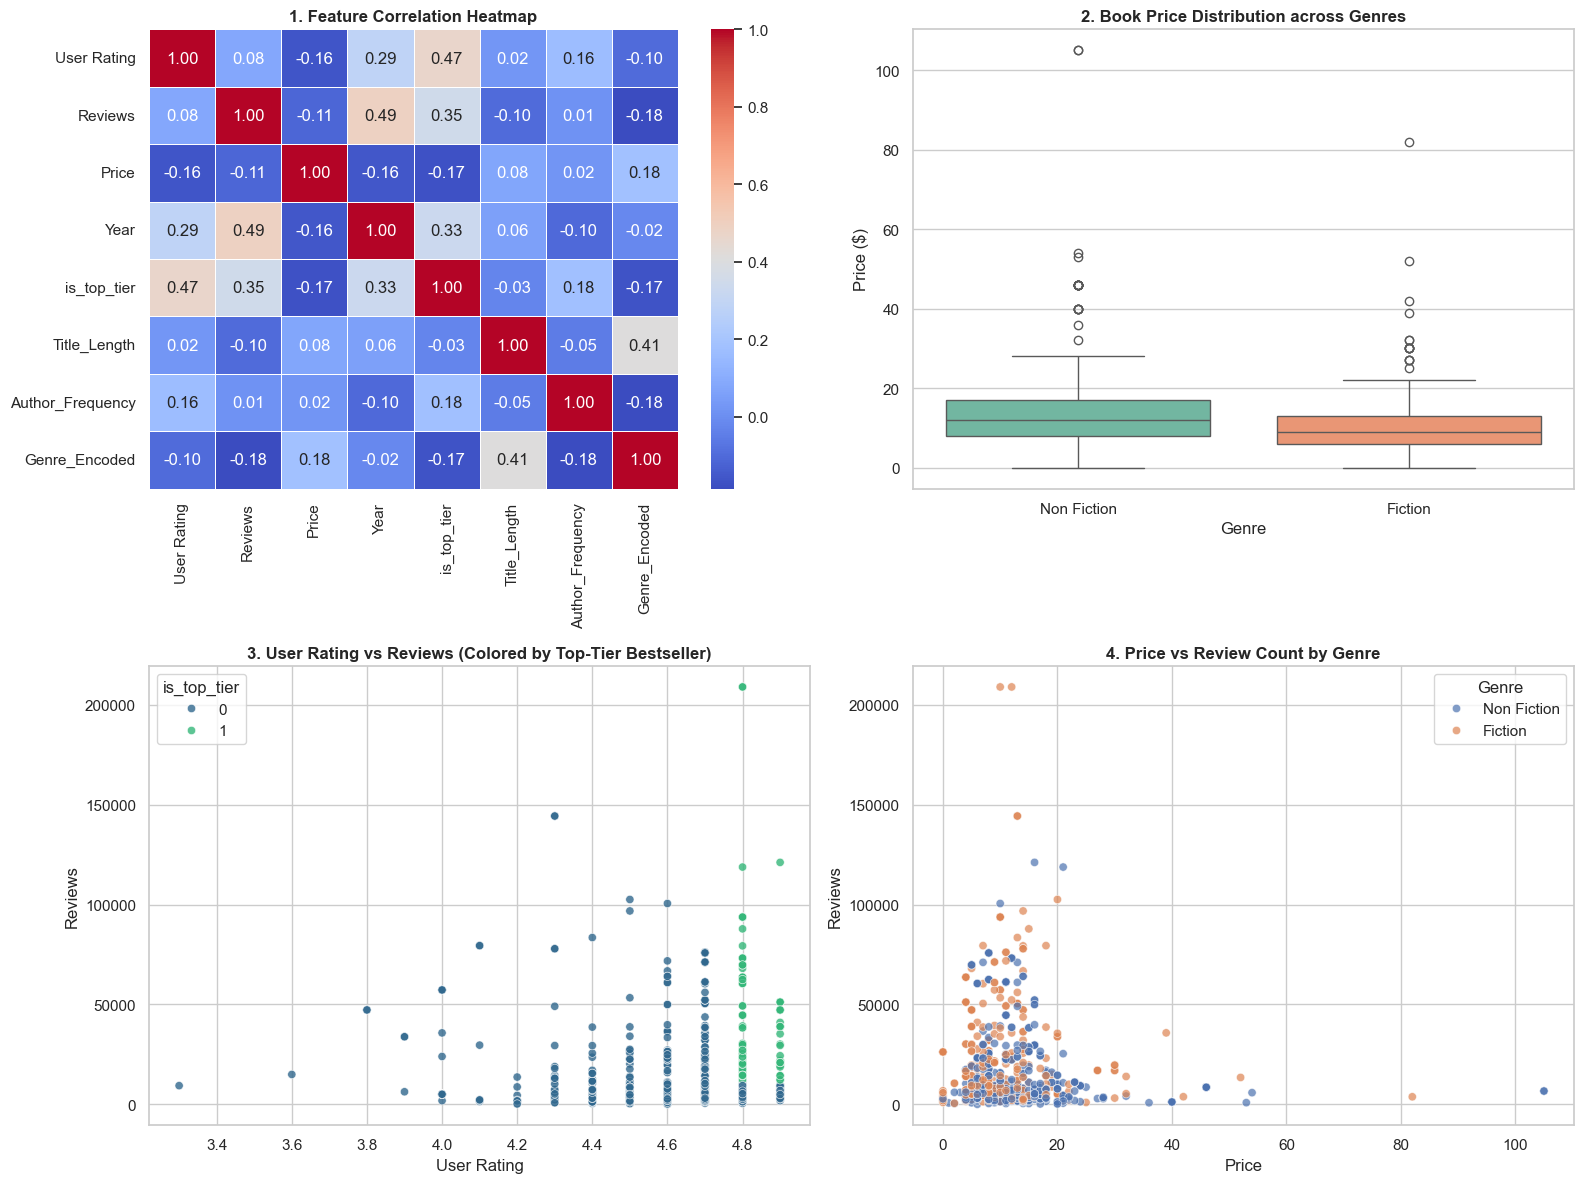

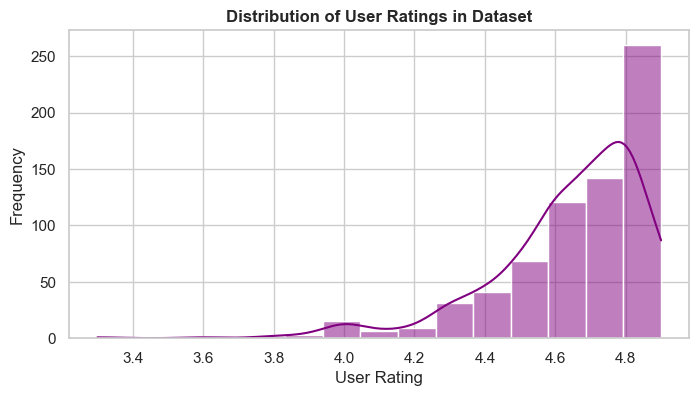

C:\Users\RUDZANI   NETHENGWE\AppData\Local\Temp\ipykernel_16824\1025977050.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


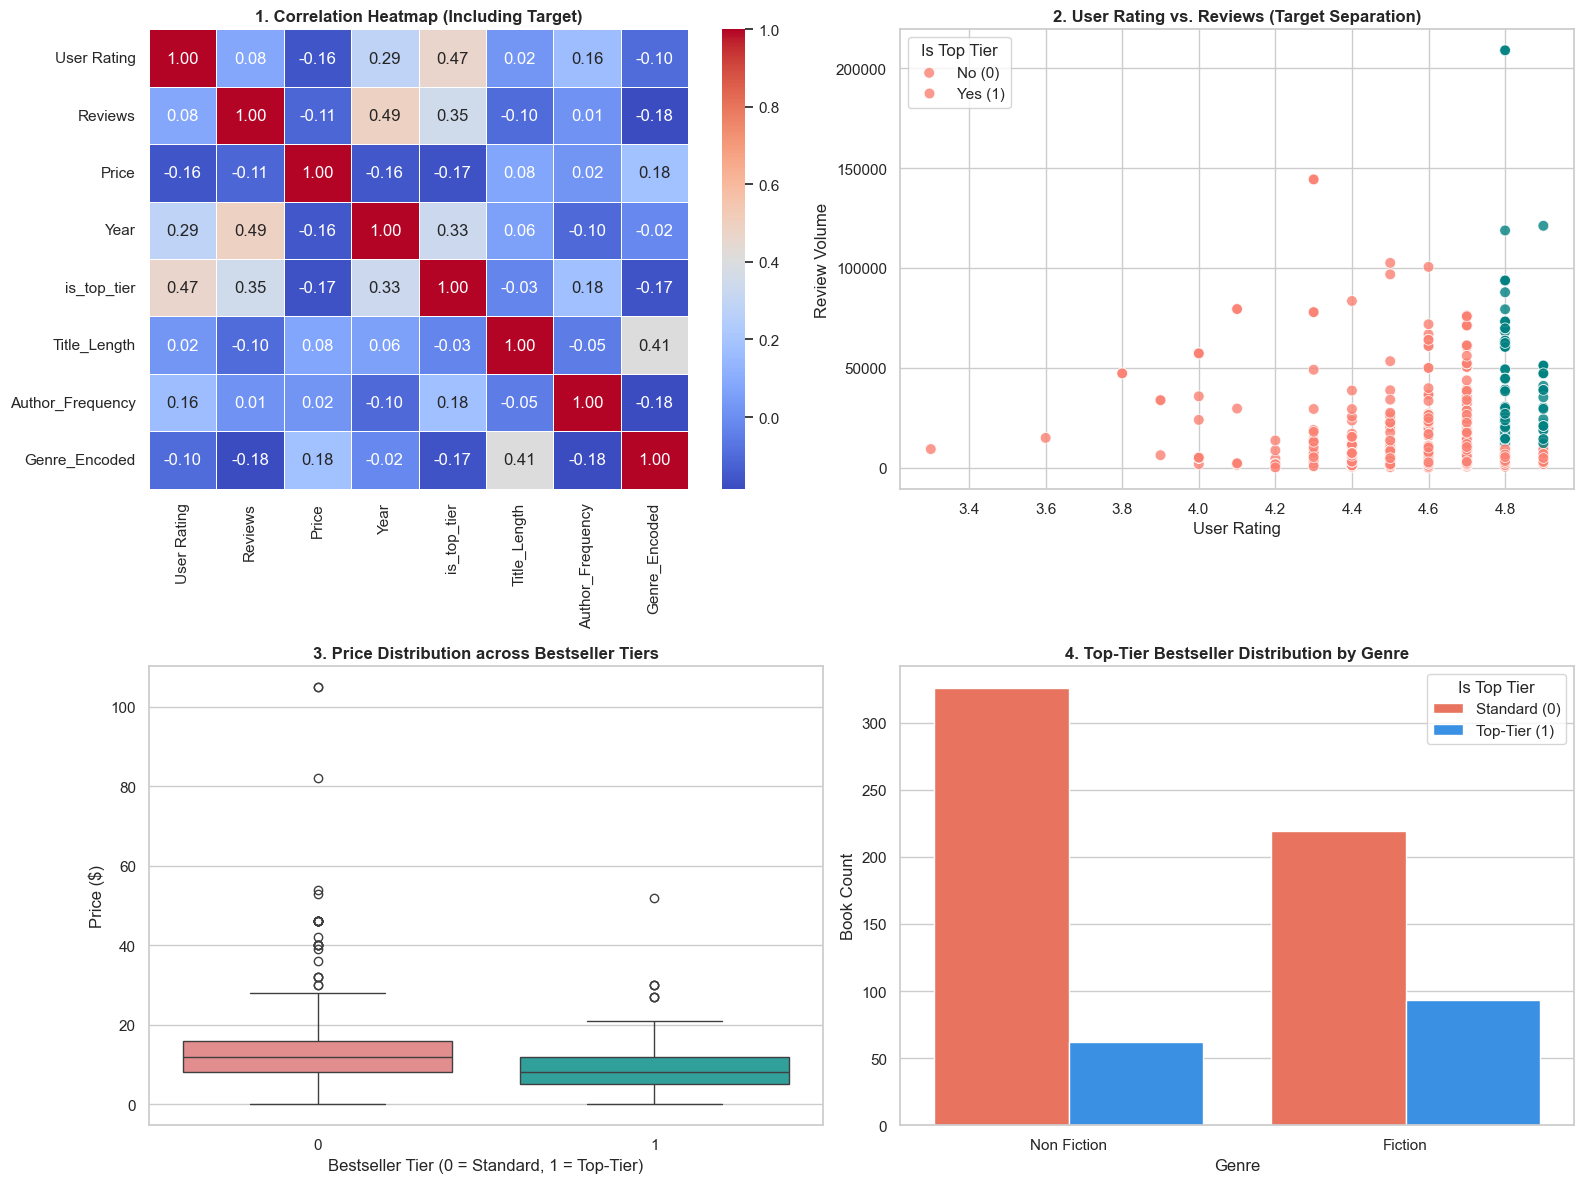

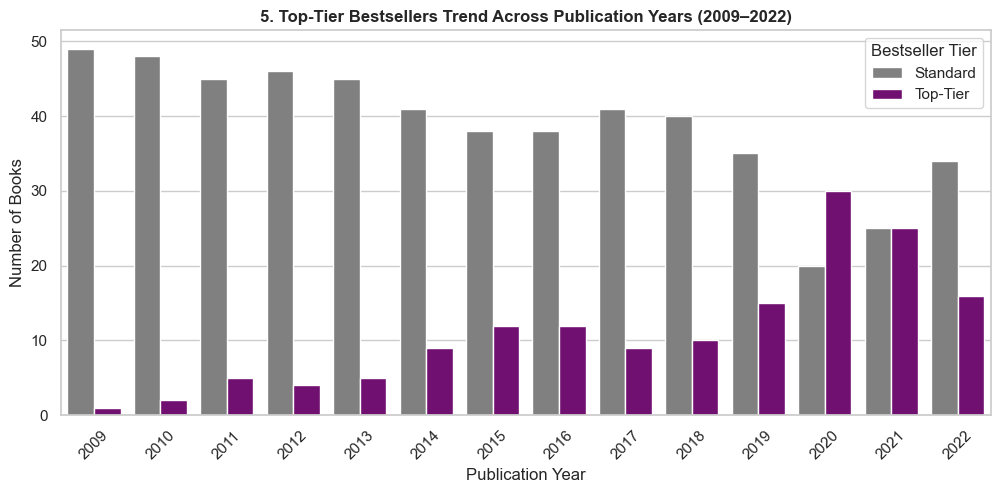

In [4]:
# Create a multi-plot figure for thorough EDA
plt.figure(figsize=(16, 12))

# 1. Correlation Heatmap
plt.subplot(2, 2, 1)
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("1. Feature Correlation Heatmap", fontsize=12, fontweight='bold')

# 2. Price Distribution by Genre
plt.subplot(2, 2, 2)
sns.boxplot(x='Genre', y='Price', data=df, palette='Set2')
plt.title("2. Book Price Distribution across Genres", fontsize=12, fontweight='bold')
plt.xlabel("Genre")
plt.ylabel("Price ($)")

# 3. User Rating vs Reviews Scatter Plot colored by Target
plt.subplot(2, 2, 3)
sns.scatterplot(x='User Rating', y='Reviews', hue='is_top_tier', data=df, palette='viridis', alpha=0.8)
plt.title("3. User Rating vs Reviews (Colored by Top-Tier Bestseller)", fontsize=12, fontweight='bold')

# 4. Price vs Reviews Scatter Plot
plt.subplot(2, 2, 4)
sns.scatterplot(x='Price', y='Reviews', hue='Genre', data=df, palette='deep', alpha=0.7)
plt.title("4. Price vs Review Count by Genre", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Additional standalone distribution plot for User Ratings
plt.figure(figsize=(8, 4))
sns.histplot(df['User Rating'], bins=15, kde=True, color='purple')
plt.title("Distribution of User Ratings in Dataset", fontsize=12, fontweight='bold')
plt.xlabel("User Rating")
plt.ylabel("Frequency")
plt.show()


# 5. Feature Correlation Heatmap (Including our Target Variable)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# Create a 2x2 subplot figure and flatten axes for easy indexing
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

temp_df = df.select_dtypes(include=[np.number]).copy()
temp_df['is_top_tier'] = df['is_top_tier']

sns.heatmap(temp_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, ax=axes[0])
axes[0].set_title("1. Correlation Heatmap (Including Target)", fontsize=12, fontweight='bold')

# 6. User Rating vs. Reviews (Colored by Top-Tier Bestseller Status)
sns.scatterplot(
    x='User Rating', y='Reviews', hue='is_top_tier', 
    data=df, palette=['salmon', 'teal'], alpha=0.8, s=60, ax=axes[1]
)
axes[1].set_title("2. User Rating vs. Reviews (Target Separation)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("User Rating")
axes[1].set_ylabel("Review Volume")
axes[1].legend(title="Is Top Tier", labels=['No (0)', 'Yes (1)'])


# 7. Price Distribution by Bestseller Tier (Boxplot)
sns.boxplot(
    x='is_top_tier', y='Price', data=df, palette=['lightcoral', 'lightseagreen'], ax=axes[2]
)
axes[2].set_title("3. Price Distribution across Bestseller Tiers", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Bestseller Tier (0 = Standard, 1 = Top-Tier)")
axes[2].set_ylabel("Price ($)")


# 8. Proportion of Top-Tier Bestsellers Across Genres (Countplot/Bar)
sns.countplot(
    x='Genre', hue='is_top_tier', data=df, palette=['tomato', 'dodgerblue'], ax=axes[3]
)
axes[3].set_title("4. Top-Tier Bestseller Distribution by Genre", fontsize=12, fontweight='bold')
axes[3].set_xlabel("Genre")
axes[3].set_ylabel("Book Count")
axes[3].legend(title="Is Top Tier", labels=['Standard (0)', 'Top-Tier (1)'])

plt.tight_layout()
plt.show()


# Additional Plot: Top-Tier Distribution Across Publication Years
plt.figure(figsize=(12, 5))
sns.countplot(x='Year', hue='is_top_tier', data=df, palette=['gray', 'purple'])
plt.title("5. Top-Tier Bestsellers Trend Across Publication Years (2009–2022)", fontsize=12, fontweight='bold')
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.xticks(rotation=45)
plt.legend(title="Bestseller Tier", labels=['Standard', 'Top-Tier'])
plt.show()

b. Feature Selection & Preprocessing

In [5]:
# Feature selection without target leakage
# The target is defined using User Rating and Reviews, so these two columns must
# NOT be predictors for a fair test: doing so would let the model see the answer.
# The original dataset and engineered target remain unchanged.

import statsmodels.api as sm
from sklearn.model_selection import GroupShuffleSplit

candidate_features = ['Price', 'Year', 'Title_Length', 'Genre_Encoded']
y_target = df['is_top_tier'].astype(int)

# Split by book title so repeated editions/records of the same title cannot appear
# in both train and test. This is a grouped 80/20 holdout with random_state=42.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(
    splitter.split(df[candidate_features], y_target, groups=df['Name'].astype(str))
)

X_train_candidates = df.iloc[train_idx][candidate_features].copy()
X_test_candidates = df.iloc[test_idx][candidate_features].copy()
y_train = y_target.iloc[train_idx].to_numpy()
y_test = y_target.iloc[test_idx].to_numpy()

# Statistical feature selection is fitted on TRAINING DATA ONLY.
X_train_sm = sm.add_constant(X_train_candidates.astype(float), has_constant='add')
try:
    logit_result = sm.Logit(y_train, X_train_sm).fit(disp=False, maxiter=200)
    p_values = logit_result.pvalues.drop(labels=['const'], errors='ignore')
    significant_features = p_values[p_values < 0.05].index.tolist()
    print("Training-only Logit feature selection completed.")
    print(logit_result.summary())
    print("\\nTraining-only p-values:")
    print(p_values.sort_values())
except Exception as exc:
    print("Training-only Logit feature selection was unstable:", repr(exc))
    significant_features = []

# If the small dataset yields no stable p<0.05 features, retain the predeclared
# independent predictors rather than creating an empty model.
if not significant_features:
    significant_features = candidate_features.copy()
    print("No stable p<0.05 features; using all predeclared independent predictors.")

X_train = X_train_candidates[significant_features].to_numpy(dtype=float)
X_test = X_test_candidates[significant_features].to_numpy(dtype=float)

print("\\nSelected independent predictors:", significant_features)
print(f"Training rows: {len(train_idx)} | Test rows: {len(test_idx)}")
print("Shared title groups:", len(set(df.iloc[train_idx]['Name']) & set(df.iloc[test_idx]['Name'])))
print("Train class counts:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("Test class counts:", pd.Series(y_test).value_counts().sort_index().to_dict())


Training-only Logit feature selection completed.
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  558
Model:                          Logit   Df Residuals:                      553
Method:                           MLE   Df Model:                            4
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                  0.1440
Time:                        09:45:27   Log-Likelihood:                -255.14
converged:                       True   LL-Null:                       -298.06
Covariance Type:            nonrobust   LLR p-value:                 1.008e-17
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const          -444.4740     62.730     -7.086      0.000    -567.422    -321.526
Price            -0.0570      0.019     -3.006      0.003      -0.094    

Train-Test Split & Scaling

To reduce leakage, the notebook now splits by book title before feature selection. This prevents repeated records for the same title from appearing in both subsets. The target definition and original dataset are unchanged. User Rating and Reviews are excluded from predictors because they directly define the target. The statistical feature-selection step is fitted on the training subset only. Scaling parameters are then learned from training data and applied unchanged to the test data.

In [6]:
# Standardize using training-set statistics only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1.0  # avoid division by zero for constant features

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print(f"Training Data Shape: {X_train_scaled.shape}")
print(f"Testing Data Shape: {X_test_scaled.shape}")
print("Scaling means learned from training data only:", mean)
print("Scaling standard deviations learned from training data only:", std)


Training Data Shape: (558, 3)
Testing Data Shape: (142, 3)
Scaling means learned from training data only: [1.26469534e+01 2.01547312e+03 5.73476703e-01]
Scaling standard deviations learned from training data only: [8.9185331  3.98498454 0.49457171]


c. Build and Train Logistic Regression

Starting Training | Samples: 558, Features: 3, Iterations: 2000, Learning Rate: 0.1
Iteration 1/2000 | Loss (Binary Cross-Entropy): 0.69315
Iteration 500/2000 | Loss (Binary Cross-Entropy): 0.45833
Iteration 1000/2000 | Loss (Binary Cross-Entropy): 0.45828
Iteration 1500/2000 | Loss (Binary Cross-Entropy): 0.45828
Iteration 2000/2000 | Loss (Binary Cross-Entropy): 0.45828
Training Complete!

FINAL TRAINED MODEL PARAMETERS:
Trained Weights : [-0.5071065   0.88567044 -0.24893766]
Trained Bias    : -1.5444


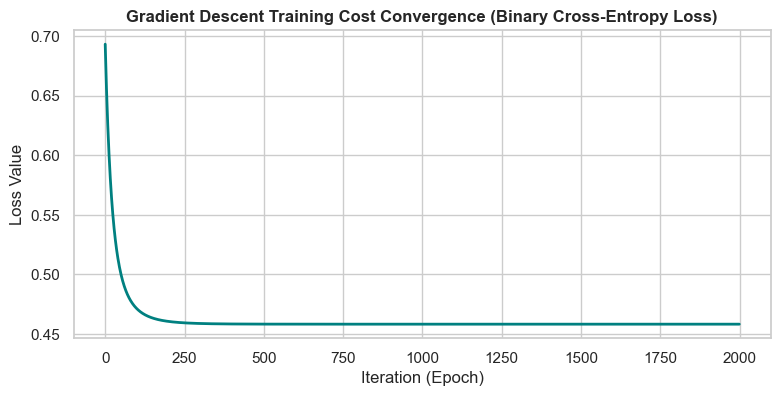

In [7]:
# ==============================================================================
# BUILD LOGISTIC REGRESSION MODEL: CLASS DEFINITION & HYPERPARAMETERS
# ==============================================================================

class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.01, n_iterations=2000):
        """
        INITIALIZATION & HYPERPARAMETERS:
        ---------------------------------
        1. learning_rate (alpha): Controls the step size during gradient descent optimization. 
           - Set to 0.1 to ensure quick and stable convergence without overshooting.
        2. n_iterations (epochs): The total number of passes the training algorithm makes 
           over the entire dataset. Set to 2,000 iterations.
        3. weights: Model coefficients assigned to each input feature (initialized to None, then zeros).
        4. bias: The intercept term (initialized to 0.0).
        5. cost_history: A list to track the Binary Cross-Entropy loss at each iteration.
        """
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = 0.0
        self.cost_history = []
        
    def _sigmoid(self, z):
        """
        ACTIVATION FUNCTION (Sigmoid):
        ------------------------------
        Maps any real-valued number into a probability value between 0 and 1.
        Formula: sigma(z) = 1 / (1 + e^(-z))
        'np.clip' is used to prevent numerical overflow/underflow warnings in exponential calculations.
        """
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
    
    def fit(self, X, y):
        """
        MODEL TRAINING PROCESS (Gradient Descent Optimization):
        -------------------------------------------------------
        This method trains the logistic regression model using batch gradient descent.
        """
        n_samples, n_features = X.shape
        
        # 1. Parameter Initialization:
        # Initialize weights vector with zeros for all features, and bias to 0.0.
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        
        print(f"Starting Training | Samples: {n_samples}, Features: {n_features}, Iterations: {self.n_iterations}, Learning Rate: {self.lr}")
        
        # 2. Iterative Optimization Loop (Epochs)
        for i in range(self.n_iterations):
            
            # --- STEP A: FORWARD PASS ---
            # Calculate the linear combination: z = X * w + b
            linear_model = np.dot(X, self.weights) + self.bias
            
            # Pass linear output through the sigmoid function to get predicted probabilities (y_hat)
            y_predicted = self._sigmoid(linear_model)
            
            # --- STEP B: GRADIENT COMPUTATION (Partial Derivatives) ---
            # Calculate the partial derivatives of the cost function with respect to weights (dw) and bias (db)
            # Formulas derived via chain rule:
            # dw = (1 / n) * X^T * (y_predicted - y)
            # db = (1 / n) * sum(y_predicted - y)
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            # --- STEP C: PARAMETER UPDATE (Gradient Descent Step) ---
            # Update weights and bias by stepping in the opposite direction of the gradient
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
            # --- STEP D: LOSS CALCULATION (Binary Cross-Entropy / Log Loss) ---
            # Measures how far our predictions are from the actual labels (y)
            # Loss = -1/n * sum( y*log(y_hat) + (1-y)*log(1-y_hat) )
            epsilon = 1e-15 # Small constant added to prevent log(0) errors
            y_predicted_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            cost = -np.mean(y * np.log(y_predicted_clipped) + (1 - y) * np.log(1 - y_predicted_clipped))
            
            # Store cost history for convergence visualization
            self.cost_history.append(cost)
            
            # Print progress every 500 iterations
            if (i + 1) % 500 == 0 or i == 0:
                print(f"Iteration {i+1}/{self.n_iterations} | Loss (Binary Cross-Entropy): {cost:.5f}")
                
        print("Training Complete!\n")
            
    def predict_proba(self, X):
        """Returns the calculated probability scores (between 0 and 1) for given input data."""
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)
    
    def predict(self, X, threshold=0.5):
        """
        Classifies inputs into 0 or 1 based on the decision threshold (default = 0.5).
        If probability >= 0.5, predict 1 (Top-Tier Bestseller), else 0.
        """
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

# ==============================================================================
# INSTANTIATING AND TRAINING THE MODEL
# ==============================================================================

# Hyperparameters setup: Learning Rate = 0.1, Iterations = 2000
scratch_model = LogisticRegressionScratch(learning_rate=0.1, n_iterations=2000)

# Execute training on our standardized training dataset
scratch_model.fit(X_train_scaled, y_train)

# Display final learned parameters
print("="*50)
print("FINAL TRAINED MODEL PARAMETERS:")
print("="*50)
print(f"Trained Weights : {scratch_model.weights}")
print(f"Trained Bias    : {scratch_model.bias:.4f}")
print("="*50)

# Plot Training Loss Convergence Curve
plt.figure(figsize=(9, 4))
plt.plot(scratch_model.cost_history, color='teal', linewidth=2)
plt.title("Gradient Descent Training Cost Convergence (Binary Cross-Entropy Loss)", fontsize=12, fontweight='bold')
plt.xlabel("Iteration (Epoch)")
plt.ylabel("Loss Value")
plt.show()

d. Comprehensive Model Performance Analysis

IN-DEPTH MODEL PERFORMANCE ANALYSIS
Accuracy  : 80.28%
Precision : 0.5294
Recall    : 0.3103
F1-Score  : 0.3913
ROC-AUC   : 0.8151

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.88       113
           1       0.53      0.31      0.39        29

    accuracy                           0.80       142
   macro avg       0.68      0.62      0.64       142
weighted avg       0.78      0.80      0.78       142



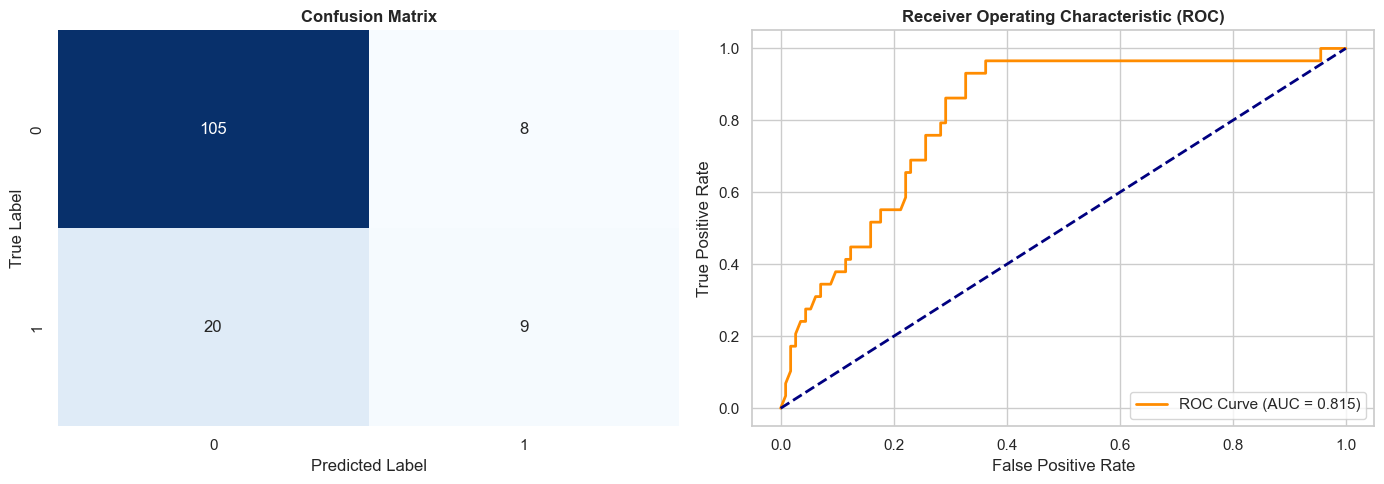

In [8]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

y_pred = scratch_model.predict(X_test_scaled)
y_prob = scratch_model.predict_proba(X_test_scaled)

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("="*45)
print("IN-DEPTH MODEL PERFORMANCE ANALYSIS")
print("="*45)
print(f"Accuracy  : {acc*100:.2f}%")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("="*45)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Visualizing Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix Heatmap
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

PREDICTION VS. ACTUAL COMPARISON TABLE (First 15 Test Samples)


,Price,Year,Genre_Encoded,Predicted Probability,Predicted Class (Y_pred),Actual Class (Y_true),Match (Correct?)
0,17.0,2009.0,1.0,0.0309,0,0,True
1,13.0,2009.0,0.0,0.0621,0,0,True
2,14.0,2009.0,1.0,0.0364,0,0,True
3,15.0,2009.0,0.0,0.0558,0,0,True
4,6.0,2009.0,1.0,0.0563,0,0,True
5,12.0,2009.0,0.0,0.0655,0,0,True
6,14.0,2009.0,1.0,0.0364,0,0,True
7,14.0,2009.0,1.0,0.0364,0,0,True
8,12.0,2009.0,1.0,0.0407,0,0,True
9,53.0,2009.0,1.0,0.0041,0,0,True



PREDICTION VS. ACTUAL PERFORMANCE SUMMARY
Total Test Samples Evaluated : 142
Correct Predictions (Match)  : 114
Incorrect Predictions (Miss) : 28
Actual vs Predicted Accuracy : 80.28%


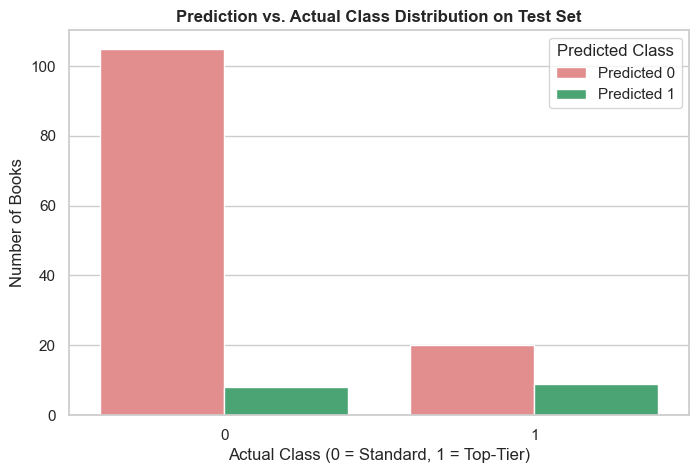

In [9]:
# ==============================================================================
# PREDICTION VS. ACTUAL COMPARISON ANALYSIS 
# ==============================================================================

# 1. Generate probabilities and binary predictions on the test set
y_probabilities = scratch_model.predict_proba(X_test_scaled)
y_predictions = scratch_model.predict(X_test_scaled, threshold=0.5)

# 2. Invert-scale X_test back to original feature units
X_test_original = (X_test_scaled * std) + mean

# 3. Dynamically construct the comparison dictionary using the selected feature names
pred_dict = {}
for i, feat_name in enumerate(significant_features):
    pred_dict[feat_name] = X_test_original[:, i]

# Add prediction results
pred_dict['Predicted Probability'] = np.round(y_probabilities, 4)
pred_dict['Predicted Class (Y_pred)'] = y_predictions
pred_dict['Actual Class (Y_true)'] = y_test
pred_dict['Match (Correct?)'] = (y_predictions == y_test)

# Construct DataFrame
pred_vs_actual_df = pd.DataFrame(pred_dict)

print("="*75)
print("PREDICTION VS. ACTUAL COMPARISON TABLE (First 15 Test Samples)")
print("="*75)
display(pred_vs_actual_df.head(15))

# 4. Summary breakdown of Prediction vs Actual results
total_test = len(y_test)
correct_matches = pred_vs_actual_df['Match (Correct?)'].sum()
incorrect_matches = total_test - correct_matches

print("\n" + "="*50)
print("PREDICTION VS. ACTUAL PERFORMANCE SUMMARY")
print("="*50)
print(f"Total Test Samples Evaluated : {total_test}")
print(f"Correct Predictions (Match)  : {correct_matches}")
print(f"Incorrect Predictions (Miss) : {incorrect_matches}")
print(f"Actual vs Predicted Accuracy : {(correct_matches / total_test) * 100:.2f}%")
print("="*50)

# 5. Visualize Prediction vs Actual distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    x='Actual Class (Y_true)', hue='Predicted Class (Y_pred)', 
    data=pred_vs_actual_df, palette=['lightcoral', 'mediumseagreen']
)
plt.title("Prediction vs. Actual Class Distribution on Test Set", fontsize=12, fontweight='bold')
plt.xlabel("Actual Class (0 = Standard, 1 = Top-Tier)")
plt.ylabel("Number of Books")
plt.legend(title="Predicted Class", labels=['Predicted 0', 'Predicted 1'])
plt.show()